# makemore part 1: bigram language model

Following Karpathy's [makemore](https://www.youtube.com/watch?v=PaCmpygFfXo) lecture.

The goal: given one character, predict the next one. I build it twice:
1. by **counting** how often each pair of characters shows up
2. as a tiny **neural network** trained with gradient descent

and then check that both end up learning the same thing.

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Loading the data

~32k names, one per line.

In [2]:
with open('data/names.txt', 'r') as f:
    words = f.read().splitlines()

words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [3]:
print('number of names:', len(words))
print('shortest name:', min(len(w) for w in words))
print('longest name:', max(len(w) for w in words))

number of names: 32033
shortest name: 2
longest name: 15


## 2. First look: counting bigrams with a dict

A bigram is just two characters next to each other. I add a start token `<S>` and an end token `<E>`
so the model also learns which letters names usually **start** and **end** with.

In [4]:
b = {}
for w in words:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram = (ch1, ch2)
        b[bigram] = b.get(bigram, 0) + 1

print('unique bigrams:', len(b))

unique bigrams: 627


In [5]:
# most common bigrams
sorted(b.items(), key=lambda kv: kv[1], reverse=True)[:10]

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963)]

## 3. Counts as a 2D tensor

A dict works but a 27x27 tensor is much easier to work with.
- 26 letters + one special token `.` for both start and end (we don't need two separate ones)
- row = current char, column = next char

In [6]:
chars = sorted(list(set(''.join(words))))
stoi = {s: i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}

In [7]:
N = torch.zeros((27, 27), dtype=torch.int32)

for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        N[stoi[ch1], stoi[ch2]] += 1

print('tensor size in bytes:', N.nbytes)   # 27 * 27 * 4 bytes (int32)

tensor size in bytes: 2916


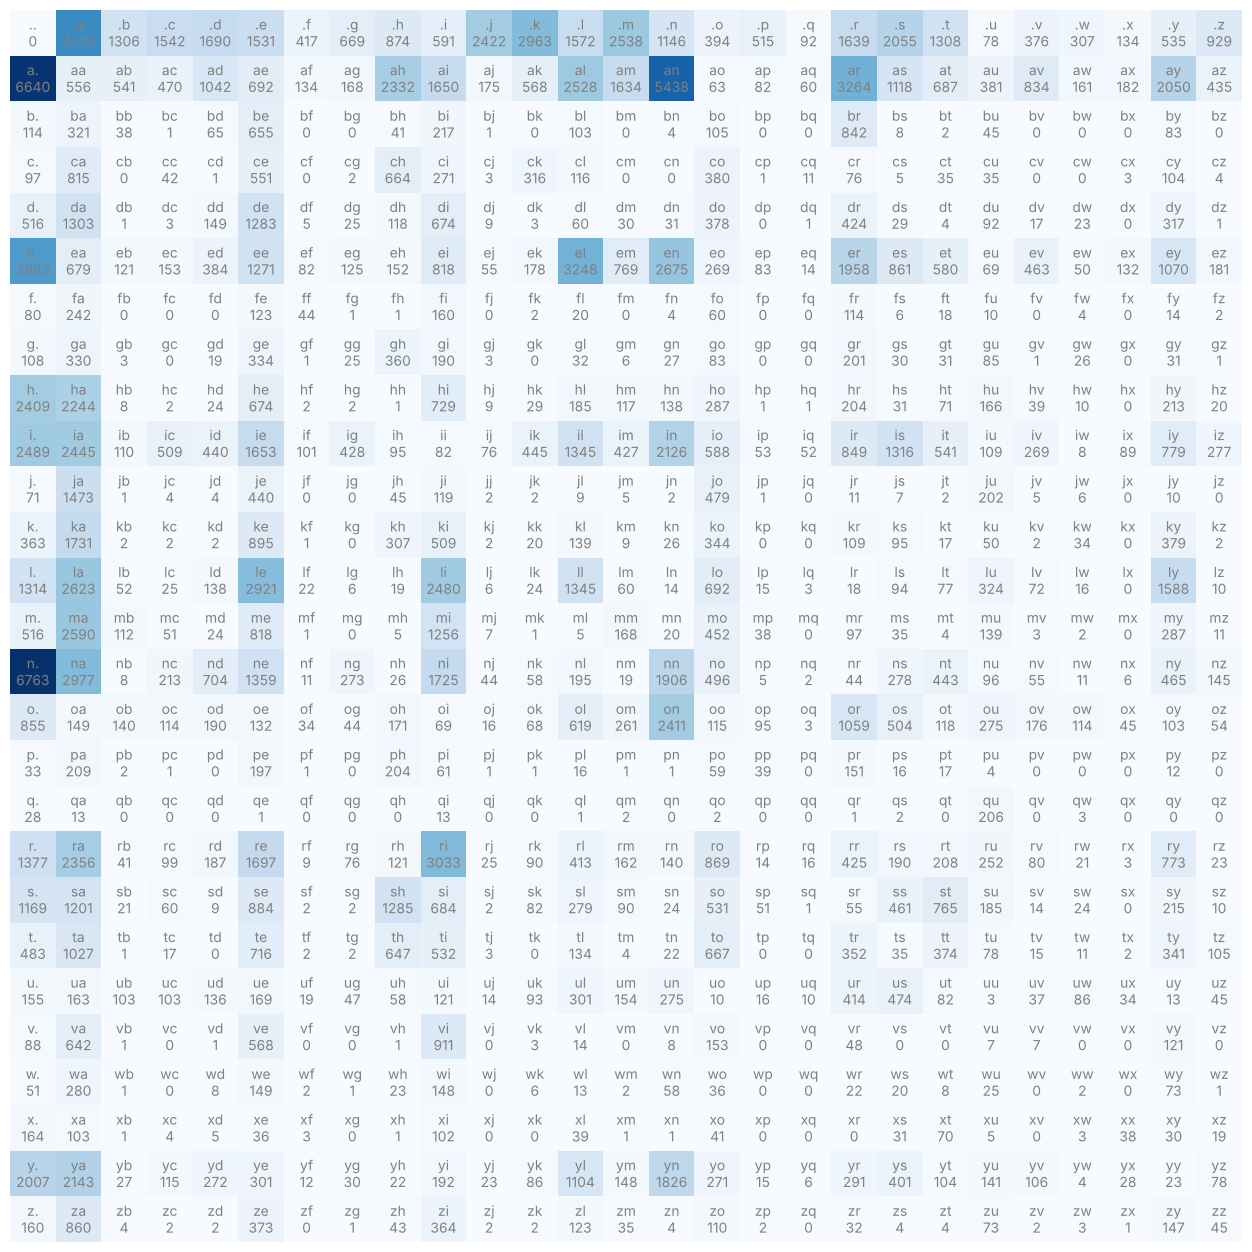

In [8]:
plt.figure(figsize=(16, 16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha='center', va='bottom', color='gray')
        plt.text(j, i, N[i, j].item(), ha='center', va='top', color='gray')
plt.axis('off');

Row 0 = which letters names start with.
Column 0 = which letters names end with.

In [9]:
N[0]

tensor([   0, 4410, 1306, 1542, 1690, 1531,  417,  669,  874,  591, 2422, 2963,
        1572, 2538, 1146,  394,  515,   92, 1639, 2055, 1308,   78,  376,  307,
         134,  535,  929], dtype=torch.int32)

## 4. From counts to probabilities + sampling

Normalize each row so it sums to 1, then that row is the distribution of the next char.

I add 1 to every count first (**smoothing**). Without it, any pair that never appeared gets probability 0,
and log(0) = -inf blows up the loss.

In [10]:
P = (N + 1).float()
P = P / P.sum(dim=1, keepdim=True)   # keepdim so broadcasting divides each row by its own sum

P[0].sum()   # sanity check, should be 1

tensor(1.)

In [11]:
# generate names: start at '.', sample next char from its row, repeat until we hit '.' again
g = torch.Generator().manual_seed(2147483647)

for i in range(5):
    out = []
    ix = 0
    while True:
        p = P[ix]
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break
    print(''.join(out))

cexze.
momasurailezitynn.
konimittain.
llayn.
ka.


Pretty bad names, but way better than random. A bigram only sees **one** character back so it has no idea what happened earlier in the name.

## 5. How good is the model? Negative log likelihood

- **likelihood** = product of the probabilities the model gave to the pairs that actually happened
- product of many small numbers gets tiny, so take the **log** (product becomes a sum)
- log of a probability is negative, so flip the sign -> **NLL**, lower is better
- divide by count -> average NLL = our **loss**

Reference point: guessing uniformly (1/27 each) gives -log(1/27) ≈ 3.29.

In [12]:
log_likelihood = 0.0
n = 0

for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        prob = P[stoi[ch1], stoi[ch2]]
        log_likelihood += torch.log(prob)
        n += 1

nll = -log_likelihood / n
print(f'average nll over the whole dataset: {nll:.4f}')

average nll over the whole dataset: 2.4544


Trying it on a weird name to see where the loss comes from. `jq` is super rare, so it gets a big penalty.
(this is also where smoothing matters, without +1 it would be inf)

In [13]:
log_likelihood = 0.0
n = 0

for w in ['andrejq']:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        prob = P[stoi[ch1], stoi[ch2]]
        logprob = torch.log(prob)
        log_likelihood += logprob
        n += 1
        print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}')

print(f'nll: {-log_likelihood / n:.4f}')

.a: 0.1376 -1.9835
an: 0.1604 -1.8302
nd: 0.0384 -3.2594
dr: 0.0770 -2.5646
re: 0.1334 -2.0143
ej: 0.0027 -5.9004
jq: 0.0003 -7.9817
q.: 0.0970 -2.3331
nll: 3.4834


## 6. Same thing as a neural network

Now instead of counting, let a neural net **learn** the probabilities by minimizing the NLL.

Training set: every bigram becomes one example
- `x` = current char (input)
- `y` = next char (label / ground truth)

First I look at just the bigrams of `emma` to understand what's going on step by step.

In [14]:
xs, ys = [], []
for w in words[:1]:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        xs.append(stoi[ch1])
        ys.append(stoi[ch2])

xs = torch.tensor(xs)
ys = torch.tensor(ys)
xs, ys

(tensor([ 0,  5, 13, 13,  1]), tensor([ 5, 13, 13,  1,  0]))

Can't feed an integer index straight into the net, so each char becomes a **one-hot** vector of size 27.

torch.Size([5, 27])


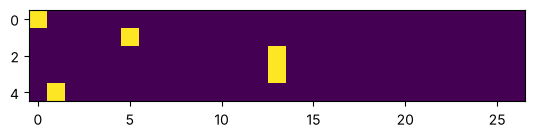

In [15]:
xenc = F.one_hot(xs, num_classes=27).float()   # float because we multiply it with W
print(xenc.shape)
plt.imshow(xenc);

**The network:** a single linear layer, 27 inputs -> 27 outputs, no bias, no activation.

- `xenc @ W` just picks out the row of `W` for that char
- outputs can be negative, so treat them as **log-counts** (logits)
- `exp()` makes them positive (like counts), then normalize -> probabilities
- exp + normalize together = **softmax**

In [16]:
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g)

logits = xenc @ W                                # log-counts
counts = logits.exp()                            # like N
probs = counts / counts.sum(1, keepdim=True)     # next-char probabilities
probs.shape

torch.Size([5, 27])

Walking through each example of `emma` to see what the (untrained) net predicts vs the real next char.

In [17]:
nlls = torch.zeros(len(xs))
for i in range(len(xs)):
    x = xs[i].item()
    y = ys[i].item()
    p = probs[i, y]
    nll = -torch.log(p)
    nlls[i] = nll
    print(f'{itos[x]}{itos[y]}: prob of correct char = {p.item():.4f}, nll = {nll.item():.4f}')

print('average nll (loss):', nlls.mean().item())

.e: prob of correct char = 0.0123, nll = 4.3993
em: prob of correct char = 0.0181, nll = 4.0146
mm: prob of correct char = 0.0267, nll = 3.6234
ma: prob of correct char = 0.0737, nll = 2.6081
a.: prob of correct char = 0.0150, nll = 4.2012
average nll (loss): 3.7693049907684326


Random weights -> high loss. Now let's train.

## 7. Training on the full dataset

In [18]:
xs, ys = [], []
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        xs.append(stoi[ch1])
        ys.append(stoi[ch2])

xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()
print('number of examples:', num)

number of examples: 228146


Notes on the loop:
- `probs[torch.arange(num), ys]` grabs the probability of the correct next char for every example at once
- `0.01 * (W**2).mean()` is **regularization**: pushes W toward 0 which makes the probabilities smoother.
  same idea as the +1 smoothing in the counting version
- lr = 50 is huge, but it works here because the problem is really simple

In [19]:
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

losses = []
for k in range(100):

    # forward pass
    xenc = F.one_hot(xs, num_classes=27).float()
    logits = xenc @ W
    counts = logits.exp()
    probs = counts / counts.sum(1, keepdim=True)
    loss = -probs[torch.arange(num), ys].log().mean() + 0.01 * (W**2).mean()
    losses.append(loss.item())

    # backward pass
    W.grad = None
    loss.backward()

    # update
    W.data += -50 * W.grad

    if k % 10 == 0:
        print(f'step {k:3d} | loss {loss.item():.4f}')

print(f'final loss: {losses[-1]:.4f}')

step   0 | loss 3.7686


step  10 | loss 2.6965


step  20 | loss 2.5823


step  30 | loss 2.5414


step  40 | loss 2.5213


...

step  60 | loss 2.5027


step  70 | loss 2.4979


step  80 | loss 2.4944


step  90 | loss 2.4919


final loss: 2.4901


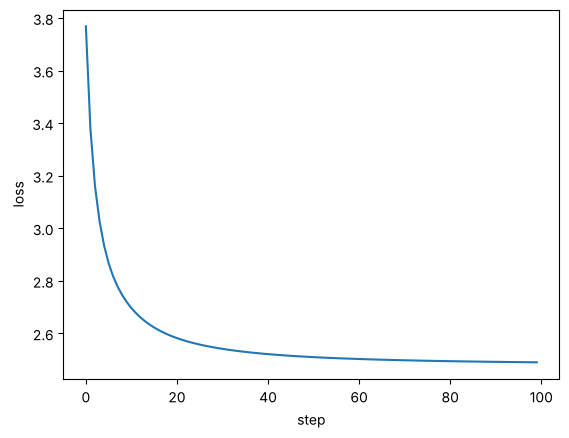

In [20]:
plt.plot(losses)
plt.xlabel('step')
plt.ylabel('loss');

Ends up close to the counting model's loss. It can't really go below it, since counting already gives the best possible bigram probabilities for this data.

## 8. Sampling from the neural net

Same seed as the counting version. If the net learned the same probabilities, the names should come out (almost) the same.

In [21]:
g = torch.Generator().manual_seed(2147483647)

with torch.no_grad():   # just sampling, no need to track gradients
    for i in range(5):
        out = []
        ix = 0
        while True:
            xenc = F.one_hot(torch.tensor([ix]), num_classes=27).float()
            logits = xenc @ W
            counts = logits.exp()
            p = counts / counts.sum(1, keepdim=True)
            ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
            out.append(itos[ix])
            if ix == 0:
                break
        print(''.join(out))

cexze.
momasurailezityha.
konimittain.
llayn.
ka.


Basically the same names as the counting model.

## Takeaways

- counting and the neural net learn the **same** thing here. after training, `W.exp()` ≈ the count table `N`
- NLL is the loss I'll keep using in every model from now on (it's cross-entropy)
- smoothing (+1 to counts) and regularization (`W**2` penalty) do the same job
- the counting approach doesn't scale: looking at 3 chars back would need a 27x27x27 table. the neural net approach does scale, which is the whole point of the next lectures